In [ ]:

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:

import os

project_dir = "/content/drive/MyDrive/SkinDisNet_Project"

print(os.listdir(project_dir))


['SkinDisNet_2.zip']


In [ ]:

import os
import zipfile

project_dir = "/content/drive/MyDrive/SkinDisNet_Project"
zip_path = os.path.join(project_dir, "SkinDisNet_2.zip")
extract_dir = "/content/skindisnet_data"

os.makedirs(extract_dir, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_dir)

print("Dataset extracted successfully!")
print("Files and folders:", os.listdir(extract_dir))


Dataset extracted successfully!
Files and folders: ['Preprocessed', 'Augmented', 'SkinDisNet_Metadata.csv']


In [ ]:

import os

for root, dirs, files in os.walk(extract_dir):
    level = root.replace(extract_dir, "").count(os.sep)

    if level > 2:
        dirs[:] = []
        continue

    print("  " * level + os.path.basename(root)
          + f" [files: {len(files)}]")

    for filename in files[:8]:
        print("  " * (level + 1) + filename)


skindisnet_data [files: 1]
  SkinDisNet_Metadata.csv
  Preprocessed [files: 0]
    Tinea Corporis (TC) [files: 275]
      TC (235).jpg
      TC (19).jpg
      TC (175).jpg
      TC (187).jpg
      TC (216).jpg
      TC (111).jpg
      TC (147).jpg
      TC (96).jpg
    Atopic Dermatitis (AD) [files: 70]
      AD (23).jpg
      AD (22).jpg
      AD (34).jpg
      AD (40).jpg
      AD (3).jpg
      AD (17).jpg
      AD (43).jpg
      AD (16).jpg
    Scabies (SC) [files: 343]
      SC (220).jpg
      SC (308).jpg
      SC (73).jpg
      SC (293).jpg
      SC (323).jpg
      SC (68).jpg
      SC (281).jpg
      SC (207).jpg
    Seborrheic Dermatitis (SD) [files: 79]
      SD (44).jpg
      SD (76).jpg
      SD (62).jpg
      SD (55).jpg
      SD (26).jpg
      SD (3).jpg
      SD (52).jpg
      SD (75).jpg
    Contact Dermatitis (CD) [files: 477]
      CD (126).jpg
      CD (38).jpg
      CD (158).jpg
      CD (394).jpg
      CD (36).jpg
      CD (248).jpg
      CD (57).jpg
      CD (173).

In [ ]:

from pathlib import Path
import pandas as pd

data_dir = Path("/content/skindisnet_data/Preprocessed")
metadata_path = Path("/content/skindisnet_data/SkinDisNet_Metadata.csv")

# Count images in each original class folder
for folder in sorted(data_dir.iterdir()):
    if folder.is_dir():
        images = [
            f for f in folder.iterdir()
            if f.suffix.lower() in [".jpg", ".jpeg", ".png"]
        ]
        print(f"{folder.name}: {len(images)} images")

# Inspect the metadata CSV
df = pd.read_csv(metadata_path)

print("\nMetadata shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 10 rows:")
display(df.head(10))


Atopic Dermatitis (AD): 70 images
Contact Dermatitis (CD): 477 images
Eczema (EC): 466 images
Scabies (SC): 343 images
Seborrheic Dermatitis (SD): 79 images
Tinea Corporis (TC): 275 images

Metadata shape: (1710, 7)

Column names:
['Folder_name', 'Patient_id', 'Image_id', 'Age', 'Sex', 'Leision_location', 'Diagnosis']

First 10 rows:


,Folder_name,Patient_id,Image_id,Age,Sex,Leision_location,Diagnosis
0,Atopic Dermatitis (AD),P_001,AD (1),14.0,Female,Hand,Atopic Dermatitis
1,Atopic Dermatitis (AD),P_001,AD (2),14.0,Female,Hand,Atopic Dermatitis
2,Atopic Dermatitis (AD),P_001,AD (3),14.0,Female,Finger,Atopic Dermatitis
3,Atopic Dermatitis (AD),P_001,AD (4),14.0,Female,Finger,Atopic Dermatitis
4,Atopic Dermatitis (AD),P_001,AD (5),14.0,Female,Hand,Atopic Dermatitis
5,Atopic Dermatitis (AD),P_002,AD (6),2.1,Male,Arm,Atopic Dermatitis
6,Atopic Dermatitis (AD),P_002,AD (7),2.1,Male,Arm,Atopic Dermatitis
7,Atopic Dermatitis (AD),P_003,AD (8),23.0,Female,Arm,Atopic Dermatitis
8,Atopic Dermatitis (AD),P_003,AD (9),23.0,Female,Arm,Atopic Dermatitis
9,Atopic Dermatitis (AD),P_003,AD (10),23.0,Female,Arm,Atopic Dermatitis


In [ ]:

import pandas as pd
from pathlib import Path
from sklearn.model_selection import GroupShuffleSplit

data_dir = Path("/content/skindisnet_data/Preprocessed")
metadata_path = Path("/content/skindisnet_data/SkinDisNet_Metadata.csv")

df = pd.read_csv(metadata_path)

# Match each metadata row to its original image
image_paths = []
for _, row in df.iterrows():
    path = data_dir / row["Folder_name"] / f'{row["Image_id"]}.jpg'
    image_paths.append(str(path) if path.exists() else None)

df["image_path"] = image_paths
df = df.dropna(subset=["image_path"]).copy()

print("Matched images:", len(df))
print("Unique patients:", df["Patient_id"].nunique())
print("\nImages per diagnosis:")
print(df["Diagnosis"].value_counts())

# First split: 70% train, 30% temporary
split1 = GroupShuffleSplit(
    n_splits=1, test_size=0.30, random_state=42
)
train_idx, temp_idx = next(
    split1.split(df, groups=df["Patient_id"])
)

train_df = df.iloc[train_idx].copy()
temp_df = df.iloc[temp_idx].copy()

# Second split: temporary into roughly equal validation and test sets
split2 = GroupShuffleSplit(
    n_splits=1, test_size=0.50, random_state=42
)
val_idx, test_idx = next(
    split2.split(temp_df, groups=temp_df["Patient_id"])
)

val_df = temp_df.iloc[val_idx].copy()
test_df = temp_df.iloc[test_idx].copy()

print("\nSplit sizes:")
print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

# Verify no patient occurs in multiple splits
train_patients = set(train_df["Patient_id"])
val_patients = set(val_df["Patient_id"])
test_patients = set(test_df["Patient_id"])

assert train_patients.isdisjoint(val_patients)
assert train_patients.isdisjoint(test_patients)
assert val_patients.isdisjoint(test_patients)

print("\nPatient separation verified.")
print("\nTraining class counts:")
print(train_df["Diagnosis"].value_counts())
print("\nValidation class counts:")
print(val_df["Diagnosis"].value_counts())
print("\nTest class counts:")
print(test_df["Diagnosis"].value_counts())


Matched images: 1710
Unique patients: 416

Images per diagnosis:
Diagnosis
Contact Dermatitis       477
Eczema                   466
Scabies                  343
Tinea Corporis           275
Seborrheic Dermatitis     79
Atopic Dermatitis         70
Name: count, dtype: int64

Split sizes:
Train: 1168
Validation: 232
Test: 310

Patient separation verified.

Training class counts:
Diagnosis
Eczema                   375
Contact Dermatitis       278
Scabies                  249
Tinea Corporis           149
Seborrheic Dermatitis     69
Atopic Dermatitis         48
Name: count, dtype: int64

Validation class counts:
Diagnosis
Tinea Corporis           74
Scabies                  60
Contact Dermatitis       55
Eczema                   29
Atopic Dermatitis        10
Seborrheic Dermatitis     4
Name: count, dtype: int64

Test class counts:
Diagnosis
Contact Dermatitis       144
Eczema                    62
Tinea Corporis            52
Scabies                   34
Atopic Dermatitis         12
Sebo

In [ ]:

!pip -q install timm scikit-learn seaborn


In [ ]:

import torch
import timm
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# Select device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# Keep your existing class order and mapping
classes = sorted(df["Diagnosis"].unique())
class_to_idx = {name: i for i, name in enumerate(classes)}
idx_to_class = {i: name for name, i in class_to_idx.items()}

print("Classes:", classes)

# Get recommended preprocessing from pretrained EfficientNet
model_config = timm.data.resolve_model_data_config(model)

img_size = model_config["input_size"][-1]
mean = model_config["mean"]
std = model_config["std"]

# Training transform: augmentation + normalization
train_transform = transforms.Compose([
    transforms.Resize(
        (img_size, img_size),
        interpolation=transforms.InterpolationMode.BICUBIC
    ),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

# Validation and test transform: no random augmentation
eval_transform = transforms.Compose([
    transforms.Resize(
        (img_size, img_size),
        interpolation=transforms.InterpolationMode.BICUBIC
    ),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

class SkinDataset(Dataset):
    def __init__(self, frame, transform):
        self.frame = frame.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]

        image = Image.open(row["image_path"]).convert("RGB")
        image = self.transform(image)

        label = class_to_idx[row["Diagnosis"]]

        return image, torch.tensor(label, dtype=torch.long)

# Create datasets using the existing patient-level splits
train_dataset = SkinDataset(train_df, train_transform)
val_dataset = SkinDataset(val_df, eval_transform)
test_dataset = SkinDataset(test_df, eval_transform)

# Create DataLoaders
train_loader = DataLoader(
    train_dataset, batch_size=16,
    shuffle=True, num_workers=2
)

val_loader = DataLoader(
    val_dataset, batch_size=16,
    shuffle=False, num_workers=2
)

test_loader = DataLoader(
    test_dataset, batch_size=16,
    shuffle=False, num_workers=2
)

print("\nDataLoaders ready!")
print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))
print("Image size:", img_size)


Device: cpu
Classes: ['Atopic Dermatitis', 'Contact Dermatitis', 'Eczema', 'Scabies', 'Seborrheic Dermatitis', 'Tinea Corporis']

DataLoaders ready!
Train batches: 73
Validation batches: 15
Test batches: 20
Image size: 224


Epoch 1/8 | Train loss: 3.8739 | Validation loss: 3.3976
Epoch 2/8 | Train loss: 3.4739 | Validation loss: 3.2038
Epoch 3/8 | Train loss: 3.0722 | Validation loss: 3.1032
Epoch 4/8 | Train loss: 2.9352 | Validation loss: 3.0208
Epoch 5/8 | Train loss: 2.6730 | Validation loss: 2.9532
Epoch 6/8 | Train loss: 2.5833 | Validation loss: 2.8899
Epoch 7/8 | Train loss: 2.5242 | Validation loss: 2.8223
Epoch 8/8 | Train loss: 2.3686 | Validation loss: 2.7671
Best validation loss: 2.7671381111802726


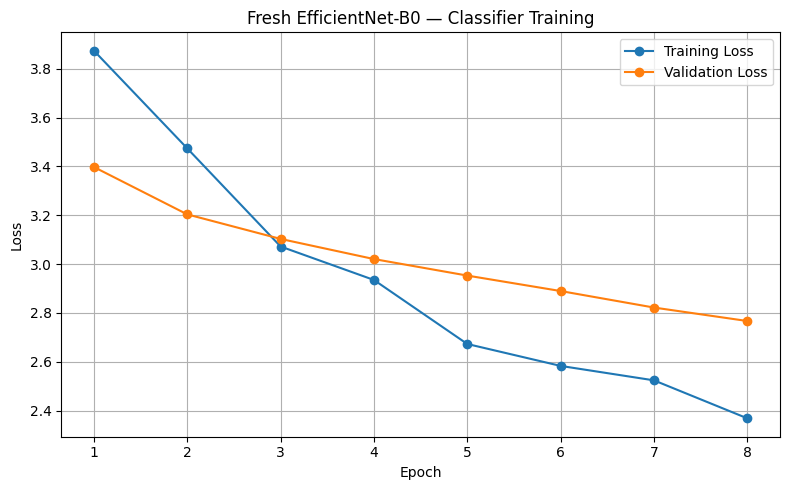

In [ ]:

import torch
import torch.nn as nn
import timm
import numpy as np
import copy
import matplotlib.pyplot as plt
from sklearn.utils.class_weight import compute_class_weight

# Start with a fresh pretrained EfficientNet-B0
model = timm.create_model(
    "efficientnet_b0",
    pretrained=True,
    num_classes=len(classes)
).to(device)

# Freeze the feature extractor
for param in model.parameters():
    param.requires_grad = False

# Train only the classifier
for param in model.classifier.parameters():
    param.requires_grad = True

# Calculate class weights from training data only
y_train = train_df["Diagnosis"].map(class_to_idx).values

weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(classes)),
    y=y_train
)

class_weights = torch.tensor(
    weights, dtype=torch.float32, device=device
)

criterion = nn.CrossEntropyLoss(weight=class_weights)

optimizer = torch.optim.AdamW(
    model.classifier.parameters(),
    lr=1e-4,
    weight_decay=1e-3
)

def evaluate_loss(model, loader):
    model.eval()
    total_loss = 0.0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            logits = model(images)
            loss = criterion(logits, labels)

            total_loss += loss.item() * labels.size(0)
            total += labels.size(0)

    return total_loss / total

# Track losses and save the best validation checkpoint
train_losses_new = []
val_losses_new = []

best_val_loss_new = float("inf")
best_state_new = None
epochs = 8

for epoch in range(epochs):
    model.train()
    model.eval()
    model.classifier.train()

    running_loss = 0.0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        logits = model(images)
        loss = criterion(logits, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * labels.size(0)
        total += labels.size(0)

    train_loss = running_loss / total
    val_loss = evaluate_loss(model, val_loader)

    train_losses_new.append(train_loss)
    val_losses_new.append(val_loss)

    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"Train loss: {train_loss:.4f} | "
        f"Validation loss: {val_loss:.4f}"
    )

    if val_loss < best_val_loss_new:
        best_val_loss_new = val_loss
        best_state_new = copy.deepcopy(model.state_dict())

# Restore best checkpoint
if best_state_new is not None:
    model.load_state_dict(best_state_new)

print("Best validation loss:", best_val_loss_new)

plt.figure(figsize=(8, 5))
plt.plot(range(1, epochs + 1), train_losses_new,
         marker="o", label="Training Loss")
plt.plot(range(1, epochs + 1), val_losses_new,
         marker="o", label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Fresh EfficientNet-B0 — Classifier Training")
plt.xticks(range(1, epochs + 1))
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:

model = timm.create_model(
    "efficientnet_b0",
    pretrained=True,
    num_classes=len(classes)
)

model = model.to(device)

print("EfficientNet-B0 loaded successfully.")
print("Output classes:", len(classes))


model.safetensors: reconstructing file:   0%|          |  0.00B / 21.4MB            

model.safetensors: downloading bytes:           |  0.00B            

EfficientNet-B0 loaded successfully.
Output classes: 6


Epoch 1/8 | Train loss: 0.1751 | Validation loss: 2.7768
Epoch 2/8 | Train loss: 0.0944 | Validation loss: 2.9493
Epoch 3/8 | Train loss: 0.0556 | Validation loss: 2.9664
Epoch 4/8 | Train loss: 0.0957 | Validation loss: 2.7928
Epoch 5/8 | Train loss: 0.0654 | Validation loss: 3.0031
Epoch 6/8 | Train loss: 0.0613 | Validation loss: 3.2524
Epoch 7/8 | Train loss: 0.0751 | Validation loss: 3.5032
Epoch 8/8 | Train loss: 0.0546 | Validation loss: 3.1534
Training finished. Best validation loss: 2.7767641996515207


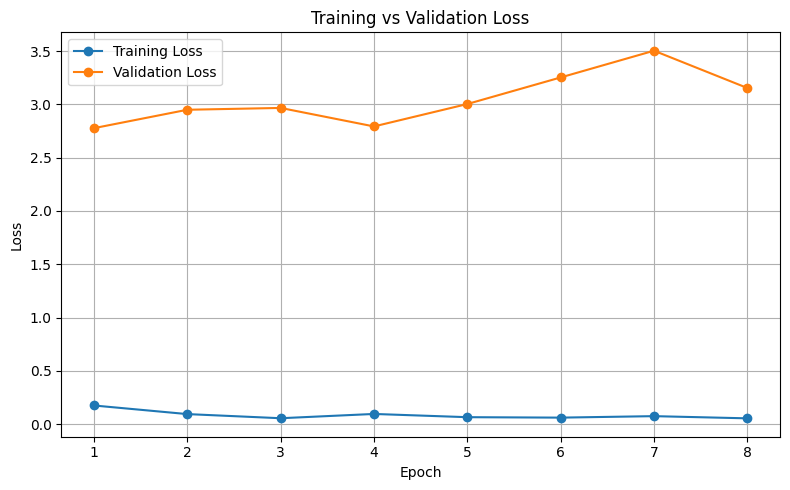

In [ ]:

from collections import Counter
from sklearn.utils.class_weight import compute_class_weight
from copy import deepcopy
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

# Calculate class weights using training data only
y_train = train_df["Diagnosis"].map(class_to_idx).values

weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(classes)),
    y=y_train
)

class_weights = torch.tensor(
    weights, dtype=torch.float32, device=device
)

criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4)

# Store losses for plotting
train_losses = []
val_losses = []

def evaluate_loss(model, loader):
    model.eval()
    total_loss = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            logits = model(images)
            loss = criterion(logits, labels)

            total_loss += loss.item() * labels.size(0)
            total += labels.size(0)

    return total_loss / total

best_val_loss = float("inf")
best_state = None
epochs = 8

for epoch in range(epochs):
    model.train()
    running_loss = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * labels.size(0)
        total += labels.size(0)

    train_loss = running_loss / total
    val_loss = evaluate_loss(model, val_loader)

    # Save each epoch's losses
    train_losses.append(train_loss)
    val_losses.append(val_loss)

    print(
        f"Epoch {epoch+1}/{epochs} | "
        f"Train loss: {train_loss:.4f} | "
        f"Validation loss: {val_loss:.4f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = deepcopy(model.state_dict())

# Restore the model with the lowest validation loss
if best_state is not None:
    model.load_state_dict(best_state)

print("Training finished. Best validation loss:", best_val_loss)

# Plot training and validation losses
plt.figure(figsize=(8, 5))
plt.plot(range(1, epochs + 1), train_losses,
         marker="o", label="Training Loss")
plt.plot(range(1, epochs + 1), val_losses,
         marker="o", label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.xticks(range(1, epochs + 1))
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


Epoch 1/8 | Train loss: 0.0204 | Validation loss: 2.7662
Epoch 2/8 | Train loss: 0.0268 | Validation loss: 2.7626
Epoch 3/8 | Train loss: 0.0194 | Validation loss: 2.7677
Epoch 4/8 | Train loss: 0.0177 | Validation loss: 2.7717
Epoch 5/8 | Train loss: 0.0182 | Validation loss: 2.7614
Epoch 6/8 | Train loss: 0.0203 | Validation loss: 2.7611
Epoch 7/8 | Train loss: 0.0182 | Validation loss: 2.7694
Epoch 8/8 | Train loss: 0.0170 | Validation loss: 2.7594
Best validation loss: 2.7593875876788436


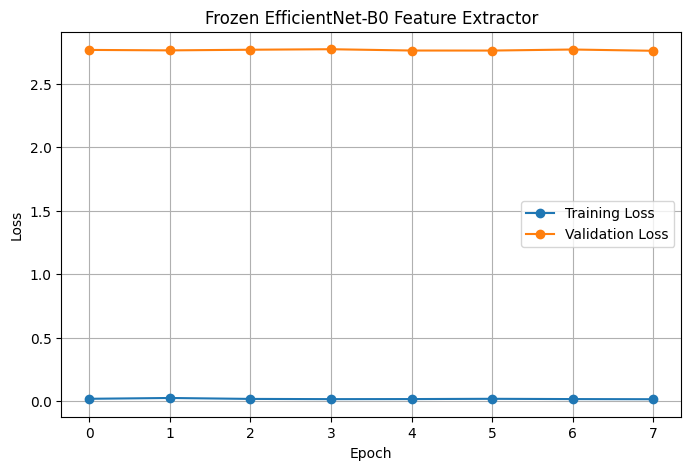

In [ ]:

import torch
import torch.nn as nn
import copy
import matplotlib.pyplot as plt

# Freeze the pretrained feature extractor
for param in model.parameters():
    param.requires_grad = False

# Unfreeze only the final classifier
for param in model.classifier.parameters():
    param.requires_grad = True

# Use a smaller learning rate for the classifier
optimizer = torch.optim.AdamW(
    model.classifier.parameters(),
    lr=1e-4,
    weight_decay=1e-3
)

train_losses_frozen = []
val_losses_frozen = []

best_val_loss_frozen = float("inf")
best_state_frozen = copy.deepcopy(model.state_dict())

epochs_frozen = 8

for epoch in range(epochs_frozen):
    model.train()

    # Keep the frozen feature extractor in evaluation mode
    model.eval()
    model.classifier.train()

    running_loss = 0.0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        logits = model(images)
        loss = criterion(logits, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * labels.size(0)
        total += labels.size(0)

    train_loss = running_loss / total
    val_loss = evaluate_loss(model, val_loader)

    train_losses_frozen.append(train_loss)
    val_losses_frozen.append(val_loss)

    print(
        f"Epoch {epoch + 1}/{epochs_frozen} | "
        f"Train loss: {train_loss:.4f} | "
        f"Validation loss: {val_loss:.4f}"
    )

    if val_loss < best_val_loss_frozen:
        best_val_loss_frozen = val_loss
        best_state_frozen = copy.deepcopy(model.state_dict())

# Restore the best classifier checkpoint
model.load_state_dict(best_state_frozen)

print("Best validation loss:", best_val_loss_frozen)

plt.figure(figsize=(8, 5))
plt.plot(train_losses_frozen, marker="o", label="Training Loss")
plt.plot(val_losses_frozen, marker="o", label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Frozen EfficientNet-B0 Feature Extractor")
plt.legend()
plt.grid(True)
plt.show()


Test accuracy: 0.3484

Per-class report:
                       precision    recall  f1-score   support

    Atopic Dermatitis       0.00      0.00      0.00        12
   Contact Dermatitis       0.59      0.24      0.34       144
               Eczema       0.28      0.56      0.37        62
              Scabies       0.47      0.53      0.50        34
Seborrheic Dermatitis       0.07      0.33      0.12         6
       Tinea Corporis       0.41      0.35      0.38        52

             accuracy                           0.35       310
            macro avg       0.30      0.34      0.29       310
         weighted avg       0.45      0.35      0.35       310



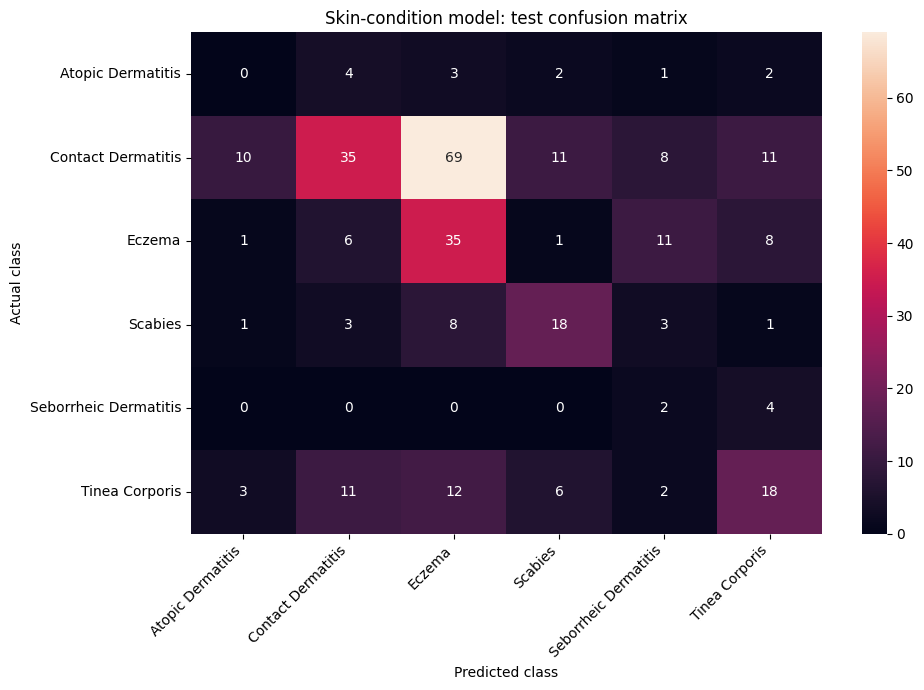

In [ ]:

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)
import matplotlib.pyplot as plt
import seaborn as sns

model.eval()
y_true = []
y_pred = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        logits = model(images)
        predictions = logits.argmax(dim=1).cpu().numpy()

        y_true.extend(labels.numpy())
        y_pred.extend(predictions)

print("Test accuracy:", round(accuracy_score(y_true, y_pred), 4))

print("\nPer-class report:")
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(classes))),
    target_names=classes,
    zero_division=0
))

cm = confusion_matrix(
    y_true, y_pred, labels=list(range(len(classes)))
)

plt.figure(figsize=(10, 7))
sns.heatmap(
    cm, annot=True, fmt="d",
    xticklabels=classes,
    yticklabels=classes
)
plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.title("Skin-condition model: test confusion matrix")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


In [ ]:

save_path = "/content/drive/MyDrive/SkinDisNet_Project/skindisnet_efficientnet_b0.pth"

torch.save({
    "model_state_dict": model.state_dict(),
    "classes": classes,
    "img_size": 224
}, save_path)

print("Model saved to:", save_path)


Model saved to: /content/drive/MyDrive/SkinDisNet_Project/skindisnet_efficientnet_b0.pth


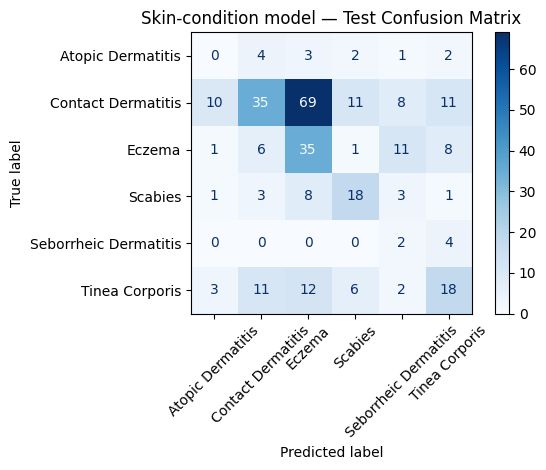

In [ ]:

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    labels=list(range(len(classes))),
    display_labels=classes,
    xticks_rotation=45,
    cmap="Blues",
    values_format="d"
)

plt.title("Skin-condition model — Test Confusion Matrix")
plt.tight_layout()
plt.show()


In [ ]:

# Check class order and label mapping

print("Classes used by the model:")
print(classes)

print("\nClass-to-index mapping:")
print(class_to_idx)

print("\nTraining samples per class:")
print(train_df["Diagnosis"].value_counts())

print("\nValidation samples per class:")
print(val_df["Diagnosis"].value_counts())

print("\nTest samples per class:")
print(test_df["Diagnosis"].value_counts())

# Verify the mapping is consistent
assert len(classes) == len(class_to_idx)
assert set(classes) == set(class_to_idx.keys())

print("\nClass mapping checks passed.")


Classes used by the model:
['Atopic Dermatitis', 'Contact Dermatitis', 'Eczema', 'Scabies', 'Seborrheic Dermatitis', 'Tinea Corporis']

Class-to-index mapping:
{'Atopic Dermatitis': 0, 'Contact Dermatitis': 1, 'Eczema': 2, 'Scabies': 3, 'Seborrheic Dermatitis': 4, 'Tinea Corporis': 5}

Training samples per class:
Diagnosis
Eczema                   375
Contact Dermatitis       278
Scabies                  249
Tinea Corporis           149
Seborrheic Dermatitis     69
Atopic Dermatitis         48
Name: count, dtype: int64

Validation samples per class:
Diagnosis
Tinea Corporis           74
Scabies                  60
Contact Dermatitis       55
Eczema                   29
Atopic Dermatitis        10
Seborrheic Dermatitis     4
Name: count, dtype: int64

Test samples per class:
Diagnosis
Contact Dermatitis       144
Eczema                    62
Tinea Corporis            52
Scabies                   34
Atopic Dermatitis         12
Seborrheic Dermatitis      6
Name: count, dtype: int64

Clas

Validation Classification Report:

                       precision    recall  f1-score   support

    Atopic Dermatitis       0.11      0.20      0.14        10
   Contact Dermatitis       0.33      0.25      0.29        55
               Eczema       0.23      0.41      0.29        29
              Scabies       0.64      0.73      0.68        60
Seborrheic Dermatitis       0.08      0.50      0.14         4
       Tinea Corporis       0.85      0.30      0.44        74

             accuracy                           0.41       232
            macro avg       0.37      0.40      0.33       232
         weighted avg       0.55      0.41      0.43       232



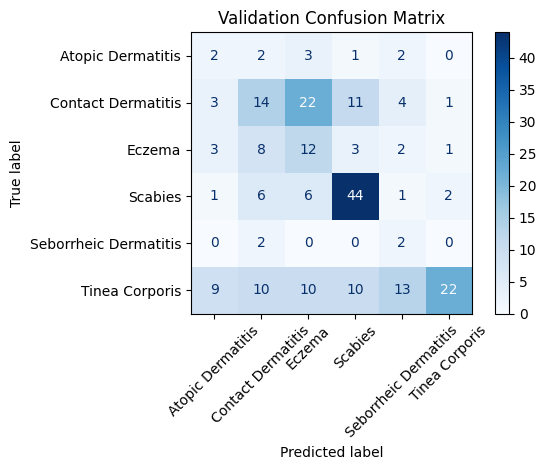

In [ ]:

import torch
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

model.eval()

y_val_true = []
y_val_pred = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)

        logits = model(images)
        predictions = torch.argmax(logits, dim=1)

        y_val_true.extend(labels.cpu().numpy())
        y_val_pred.extend(predictions.cpu().numpy())

print("Validation Classification Report:\n")
print(classification_report(
    y_val_true,
    y_val_pred,
    labels=list(range(len(classes))),
    target_names=classes,
    zero_division=0
))

cm = confusion_matrix(
    y_val_true,
    y_val_pred,
    labels=list(range(len(classes)))
)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
).plot(xticks_rotation=45, cmap="Blues", values_format="d")

plt.title("Validation Confusion Matrix")
plt.tight_layout()
plt.show()


In [ ]:

from torchvision import transforms
import timm

# Check the model's expected preprocessing
model_info = timm.data.resolve_model_data_config(model)

print("Model input configuration:")
print(model_info)

print("\nModel class count:", model.num_classes)
print("Dataset class count:", len(classes))

print("\nTraining transform:")
print(train_loader.dataset.transform)

print("\nValidation transform:")
print(val_loader.dataset.transform)


Model input configuration:
{'input_size': (3, 224, 224), 'interpolation': 'bicubic', 'mean': (0.485, 0.456, 0.406), 'std': (0.229, 0.224, 0.225), 'crop_pct': 0.875, 'crop_mode': 'center'}

Model class count: 6
Dataset class count: 6

Training transform:
Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomRotation(degrees=[-10.0, 10.0], interpolation=nearest, expand=False, fill=0)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

Validation transform:
Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


In [ ]:

from torchvision import transforms
from timm.data import resolve_model_data_config

# Read the pretrained model's recommended configuration
data_config = resolve_model_data_config(model)

img_size = data_config["input_size"][-1]
mean = data_config["mean"]
std = data_config["std"]

# Training: resize, augment, and normalize
train_transform = transforms.Compose([
    transforms.Resize(
        (img_size, img_size),
        interpolation=transforms.InterpolationMode.BICUBIC
    ),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

# Validation/test: resize and normalize only
eval_transform = transforms.Compose([
    transforms.Resize(
        (img_size, img_size),
        interpolation=transforms.InterpolationMode.BICUBIC
    ),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

print("Image size:", img_size)
print("Training transform:", train_transform)
print("Evaluation transform:", eval_transform)


Image size: 224
Training transform: Compose(
    Resize(size=(224, 224), interpolation=bicubic, max_size=None, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomRotation(degrees=[-10.0, 10.0], interpolation=nearest, expand=False, fill=0)
    ToTensor()
    Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))
)
Evaluation transform: Compose(
    Resize(size=(224, 224), interpolation=bicubic, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))
)


In [ ]:

from sklearn.metrics import accuracy_score, f1_score, classification_report
import torch

model.eval()

y_val_true = []
y_val_pred = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        y_val_true.extend(labels.cpu().numpy())
        y_val_pred.extend(predictions.cpu().numpy())

accuracy = accuracy_score(y_val_true, y_val_pred)
macro_f1 = f1_score(
    y_val_true,
    y_val_pred,
    average="macro",
    zero_division=0
)

print(f"Validation Accuracy: {accuracy:.4f}")
print(f"Validation Macro F1: {macro_f1:.4f}")

print("\nClassification Report:\n")
print(classification_report(
    y_val_true,
    y_val_pred,
    labels=list(range(len(classes))),
    target_names=classes,
    zero_division=0
))


NameError: name 'model' is not defined

In [ ]:

import os

checkpoint_path = (
    "/content/drive/MyDrive/SkinDisNet_Project/"
    "skindisnet_efficientnet_b0.pth"
)

print("Checkpoint exists:", os.path.exists(checkpoint_path))


Checkpoint exists: False


In [ ]:

from google.colab import drive
drive.mount("/content/drive")



Mounted at /content/drive


In [ ]:

import os

project_folder = "/content/drive/MyDrive/SkinDisNet_Project"

if os.path.exists(project_folder):
    print("Files in SkinDisNet_Project:")
    for root, dirs, files in os.walk(project_folder):
        for file in files:
            if file.endswith((".pth", ".pt", ".ckpt")):
                print(os.path.join(root, file))
else:
    print("Project folder not found:", project_folder)
    print("\nChecking MyDrive for model checkpoints...")

    drive_root = "/content/drive/MyDrive"
    for root, dirs, files in os.walk(drive_root):
        dirs[:] = [d for d in dirs if d not in
                   [".Trash", ".ipynb_checkpoints"]]
        for file in files:
            if file.endswith((".pth", ".pt", ".ckpt")):
                print(os.path.join(root, file))


Files in SkinDisNet_Project:
/content/drive/MyDrive/SkinDisNet_Project/skindisnet_efficientnet_b0.pth


In [ ]:

import torch
import timm

checkpoint_path = (
    "/content/drive/MyDrive/SkinDisNet_Project/"
    "skindisnet_efficientnet_b0.pth"
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load checkpoint safely
try:
    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=True
    )
except TypeError:
    checkpoint = torch.load(checkpoint_path, map_location=device)

# Recreate the model with the saved class count
classes = checkpoint["classes"]

model = timm.create_model(
    "efficientnet_b0",
    pretrained=False,
    num_classes=len(classes)
).to(device)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Model loaded successfully!")
print("Device:", device)
print("Classes:", classes)


Model loaded successfully!
Device: cpu
Classes: ['Atopic Dermatitis', 'Contact Dermatitis', 'Eczema', 'Scabies', 'Seborrheic Dermatitis', 'Tinea Corporis']


In [ ]:

required_variables = [
    "val_loader",
    "val_df",
    "class_to_idx"
]

for name in required_variables:
    print(f"{name} available:", name in globals())



val_loader available: False
val_df available: False
class_to_idx available: False


In [ ]:

import os

base_path = "/content/skindisnet_data"

print("Dataset folder exists:", os.path.exists(base_path))

if os.path.exists(base_path):
    for root, dirs, files in os.walk(base_path):
        level = root.replace(base_path, "").count(os.sep)

        if level <= 2:
            print("  " * level + os.path.basename(root) + "/")

        if level >= 2:
            dirs[:] = []


Dataset folder exists: False


In [ ]:

from google.colab import drive
import os
import zipfile

drive.mount("/content/drive")

zip_path = "/content/drive/MyDrive/SkinDisNet_Project/SkinDisNet_2.zip"
extract_path = "/content/skindisnet_data"

if not os.path.exists(zip_path):
    print("ZIP file not found:", zip_path)
else:
    os.makedirs(extract_path, exist_ok=True)

    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(extract_path)

    print("Dataset extracted successfully!")
    print("Location:", extract_path)
    print("Metadata exists:", any(
        file == "SkinDisNet_Metadata.csv"
        for _, _, files in os.walk(extract_path)
        for file in files
    ))



Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset extracted successfully!
Location: /content/skindisnet_data
Metadata exists: True


In [ ]:

import os
import pandas as pd
import numpy as np
from sklearn.model_selection import GroupShuffleSplit

base_path = "/content/skindisnet_data"

# Find the metadata CSV
metadata_path = None

for root, dirs, files in os.walk(base_path):
    if "SkinDisNet_Metadata.csv" in files:
        metadata_path = os.path.join(root, "SkinDisNet_Metadata.csv")
        break

if metadata_path is None:
    raise FileNotFoundError("SkinDisNet_Metadata.csv not found")

df = pd.read_csv(metadata_path)

print("Metadata loaded:", df.shape)
print("Columns:", df.columns.tolist())
print(df.head(2))


Metadata loaded: (1710, 7)
Columns: ['Folder_name', 'Patient_id', 'Image_id', 'Age', 'Sex', 'Leision_location', 'Diagnosis']
              Folder_name Patient_id Image_id   Age     Sex Leision_location  \
0  Atopic Dermatitis (AD)      P_001   AD (1)  14.0  Female             Hand   
1  Atopic Dermatitis (AD)      P_001   AD (2)  14.0  Female             Hand   

           Diagnosis  
0  Atopic Dermatitis  
1  Atopic Dermatitis  


In [ ]:

import os
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

base_path = "/content/skindisnet_data"
image_root = os.path.join(base_path, "Preprocessed")

# Map each metadata row to its image file
image_paths = []

for _, row in df.iterrows():
    folder = row["Folder_name"]
    image_id = str(row["Image_id"])

    # Try common image extensions
    found_path = None

    for ext in [".jpg", ".jpeg", ".png", ".JPG", ".JPEG", ".PNG"]:
        candidate = os.path.join(image_root, folder, image_id + ext)
        if os.path.isfile(candidate):
            found_path = candidate
            break

    image_paths.append(found_path)

df["image_path"] = image_paths

# Keep only rows whose image files were found
df = df.dropna(subset=["image_path"]).reset_index(drop=True)

print("Matched images:", len(df))

# Recreate the patient-level 70/30 split, then split the 30% in half
split1 = GroupShuffleSplit(
    n_splits=1, test_size=0.30, random_state=42
)
train_idx, temp_idx = next(
    split1.split(df, groups=df["Patient_id"])
)

train_df = df.iloc[train_idx].reset_index(drop=True)
temp_df = df.iloc[temp_idx].reset_index(drop=True)

split2 = GroupShuffleSplit(
    n_splits=1, test_size=0.50, random_state=42
)
val_idx, test_idx = next(
    split2.split(temp_df, groups=temp_df["Patient_id"])
)

val_df = temp_df.iloc[val_idx].reset_index(drop=True)
test_df = temp_df.iloc[test_idx].reset_index(drop=True)

# Verify that no patient appears in multiple splits
train_patients = set(train_df["Patient_id"])
val_patients = set(val_df["Patient_id"])
test_patients = set(test_df["Patient_id"])

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

print("Patient overlap:",
      bool(train_patients & val_patients)
      or bool(train_patients & test_patients)
      or bool(val_patients & test_patients))


Matched images: 1710
Train: 1168
Validation: 232
Test: 310
Patient overlap: False


In [ ]:

import torch
import timm
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from torchvision import transforms
from sklearn.metrics import accuracy_score, classification_report

# Use the class order saved with the checkpoint
class_to_idx = {name: i for i, name in enumerate(classes)}

# Match dataset labels to the checkpoint's class order
for data in [train_df, val_df, test_df]:
    data["label"] = data["Diagnosis"].map(class_to_idx)

# Use the model's expected ImageNet normalization
test_transform = transforms.Compose([
    transforms.Resize((224, 224), interpolation=transforms.InterpolationMode.BICUBIC),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225)
    )
])

class SkinDataset(Dataset):
    def __init__(self, dataframe, transform):
        self.data = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]
        image = Image.open(row["image_path"]).convert("RGB")
        image = self.transform(image)
        return image, int(row["label"])

test_dataset = SkinDataset(test_df, test_transform)
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False)

model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_preds.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

print("Test Accuracy:", round(accuracy_score(all_labels, all_preds), 4))
print("\nClassification Report:")
print(classification_report(
    all_labels,
    all_preds,
    labels=list(range(len(classes))),
    target_names=classes,
    zero_division=0
))


Test Accuracy: 0.3484

Classification Report:
                       precision    recall  f1-score   support

    Atopic Dermatitis       0.00      0.00      0.00        12
   Contact Dermatitis       0.64      0.25      0.36       144
               Eczema       0.26      0.52      0.35        62
              Scabies       0.46      0.56      0.51        34
Seborrheic Dermatitis       0.06      0.33      0.11         6
       Tinea Corporis       0.40      0.37      0.38        52

             accuracy                           0.35       310
            macro avg       0.31      0.34      0.28       310
         weighted avg       0.47      0.35      0.36       310



In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(train_losses_new, label="Training Loss")
plt.plot(val_losses_new, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

NameError: name 'train_losses_new' is not defined

<Figure size 800x500 with 0 Axes>

In [ ]:
print("Training history available:",
      "train_losses_new" in globals())

print("Validation history available:",
      "val_losses_new" in globals())

print("Model available:", "model" in globals())
print("Checkpoint classes available:", "classes" in globals())

Training history available: False
Validation history available: False
Model available: True
Checkpoint classes available: True


In [ ]:
print("Model:", type(model).__name__)
print("Classes:", classes)
print("Device:", device)

print("\nDataset sizes:")
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

print("\nLabel mapping:")
print({name: i for i, name in enumerate(classes)})

Model: EfficientNet
Classes: ['Atopic Dermatitis', 'Contact Dermatitis', 'Eczema', 'Scabies', 'Seborrheic Dermatitis', 'Tinea Corporis']
Device: cpu

Dataset sizes:
Training: 1168
Validation: 232
Testing: 310

Label mapping:
{'Atopic Dermatitis': 0, 'Contact Dermatitis': 1, 'Eczema': 2, 'Scabies': 3, 'Seborrheic Dermatitis': 4, 'Tinea Corporis': 5}


In [ ]:

import os
import copy
import torch
import torch.nn as nn
import timm

# Keep the existing model unchanged in memory.
# Create a separate model for the new experiment.
new_model = timm.create_model(
    "efficientnet_b0",
    pretrained=False,
    num_classes=len(classes)
).to(device)

# Load the saved checkpoint
checkpoint_path = (
    "/content/drive/MyDrive/SkinDisNet_Project/"
    "skindisnet_efficientnet_b0.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

new_model.load_state_dict(checkpoint["model_state_dict"])

# Freeze every parameter first
for parameter in new_model.parameters():
    parameter.requires_grad = False

# Unfreeze the final feature block and classifier
for parameter in new_model.blocks[-1].parameters():
    parameter.requires_grad = True

for parameter in new_model.classifier.parameters():
    parameter.requires_grad = True

# Loss and optimizer
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, new_model.parameters()),
    lr=1e-5,
    weight_decay=1e-4
)

print("Model prepared for partial fine-tuning.")
print("Trainable parameters:",
      sum(p.numel() for p in new_model.parameters()
          if p.requires_grad))
print("Device:", device)


Model prepared for partial fine-tuning.
Trainable parameters: 724918
Device: cpu


Epoch 1/10 | Train Loss: 0.1468 | Val Loss: 2.5299 | Val Macro F1: 0.3345
Epoch 2/10 | Train Loss: 0.1306 | Val Loss: 2.4747 | Val Macro F1: 0.3262
Epoch 3/10 | Train Loss: 0.1326 | Val Loss: 2.6213 | Val Macro F1: 0.3206
Epoch 4/10 | Train Loss: 0.1182 | Val Loss: 2.6639 | Val Macro F1: 0.3293
Epoch 5/10 | Train Loss: 0.1147 | Val Loss: 2.4447 | Val Macro F1: 0.3230
Epoch 6/10 | Train Loss: 0.1125 | Val Loss: 2.6851 | Val Macro F1: 0.3165
Epoch 7/10 | Train Loss: 0.1177 | Val Loss: 2.4434 | Val Macro F1: 0.3391
Epoch 8/10 | Train Loss: 0.1173 | Val Loss: 2.4959 | Val Macro F1: 0.3330
Epoch 9/10 | Train Loss: 0.1074 | Val Loss: 2.3513 | Val Macro F1: 0.3663
Epoch 10/10 | Train Loss: 0.1087 | Val Loss: 2.6634 | Val Macro F1: 0.3210

Training finished.
Best validation loss: 2.3513
Best checkpoint: /content/drive/MyDrive/SkinDisNet_Project/skindisnet_partial_best.pth
Training history: /content/drive/MyDrive/SkinDisNet_Project/partial_training_history.json


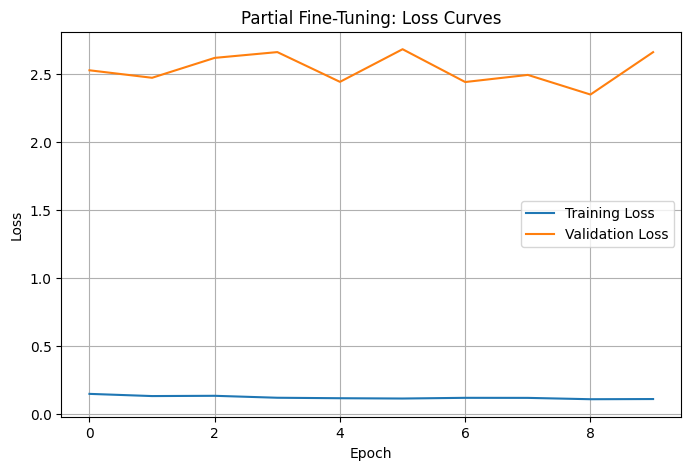

In [ ]:

import os
import json
import copy
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.metrics import f1_score

# 1. Image preprocessing
train_transform = transforms.Compose([
    transforms.Resize(
        (224, 224),
        interpolation=transforms.InterpolationMode.BICUBIC
    ),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225)
    )
])

val_transform = transforms.Compose([
    transforms.Resize(
        (224, 224),
        interpolation=transforms.InterpolationMode.BICUBIC
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225)
    )
])

# 2. Dataset
class SkinDataset(Dataset):
    def __init__(self, dataframe, transform, classes):
        self.data = dataframe.reset_index(drop=True).copy()
        self.transform = transform
        self.class_to_idx = {name: i for i, name in enumerate(classes)}
        self.data["label"] = self.data["Diagnosis"].map(
            self.class_to_idx
        )

        if self.data["label"].isna().any():
            raise ValueError("Some diagnoses do not match the class list.")

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):
        row = self.data.iloc[index]
        image = Image.open(row["image_path"]).convert("RGB")
        image = self.transform(image)
        return image, int(row["label"])

train_dataset = SkinDataset(train_df, train_transform, classes)
val_dataset = SkinDataset(val_df, val_transform, classes)

# 3. DataLoaders
train_loader = DataLoader(
    train_dataset, batch_size=16, shuffle=True, num_workers=0
)
val_loader = DataLoader(
    val_dataset, batch_size=16, shuffle=False, num_workers=0
)

# 4. Save experiment files separately from the old checkpoint
save_dir = "/content/drive/MyDrive/SkinDisNet_Project"
os.makedirs(save_dir, exist_ok=True)

best_path = os.path.join(save_dir, "skindisnet_partial_best.pth")
history_path = os.path.join(save_dir, "partial_training_history.json")

history = {
    "train_loss": [],
    "val_loss": [],
    "val_macro_f1": []
}

best_val_loss = float("inf")
best_state = None
patience = 3
epochs_without_improvement = 0
max_epochs = 10

# 5. Training loop
for epoch in range(max_epochs):
    new_model.train()
    train_total_loss = 0.0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = new_model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        train_total_loss += loss.item() * images.size(0)

    train_loss = train_total_loss / len(train_dataset)

    # Validation
    new_model.eval()
    val_total_loss = 0.0
    all_preds, all_labels = [], []

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = new_model(images)
            loss = criterion(outputs, labels)
            predictions = outputs.argmax(dim=1)

            val_total_loss += loss.item() * images.size(0)
            all_preds.extend(predictions.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    val_loss = val_total_loss / len(val_dataset)
    val_macro_f1 = f1_score(
        all_labels,
        all_preds,
        labels=list(range(len(classes))),
        average="macro",
        zero_division=0
    )

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_macro_f1"].append(float(val_macro_f1))

    print(
        f"Epoch {epoch + 1}/{max_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Macro F1: {val_macro_f1:.4f}"
    )

    # Select the best model by validation loss
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = copy.deepcopy(new_model.state_dict())
        epochs_without_improvement = 0

        torch.save({
            "model_state_dict": best_state,
            "classes": classes,
            "img_size": 224,
            "best_val_loss": best_val_loss,
            "epoch": epoch + 1
        }, best_path)
    else:
        epochs_without_improvement += 1

    # Save history after every epoch
    with open(history_path, "w") as f:
        json.dump(history, f, indent=2)

    if epochs_without_improvement >= patience:
        print("Early stopping: validation loss did not improve.")
        break

# Restore the best validation checkpoint
if best_state is not None:
    new_model.load_state_dict(best_state)

print("\nTraining finished.")
print("Best validation loss:", round(best_val_loss, 4))
print("Best checkpoint:", best_path)
print("Training history:", history_path)

# 6. Plot and display losses
plt.figure(figsize=(8, 5))
plt.plot(history["train_loss"], label="Training Loss")
plt.plot(history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Partial Fine-Tuning: Loss Curves")
plt.legend()
plt.grid(True)
plt.show()


In [ ]:

import torch
import timm
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

checkpoint_path = (
    "/content/drive/MyDrive/SkinDisNet_Project/"
    "skindisnet_partial_best.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

test_model = timm.create_model(
    "efficientnet_b0",
    pretrained=False,
    num_classes=len(checkpoint["classes"])
).to(device)

test_model.load_state_dict(checkpoint["model_state_dict"])
test_model.eval()

# Use the test dataset and loader created earlier.
# They use deterministic validation-style preprocessing.
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = test_model(images)
        predictions = outputs.argmax(dim=1)

        all_preds.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

print("Best checkpoint epoch:", checkpoint["epoch"])
print("Best validation loss:", checkpoint["best_val_loss"])
print("Test accuracy:", round(
    accuracy_score(all_labels, all_preds), 4
))

print("\nClassification Report:")
print(classification_report(
    all_labels,
    all_preds,
    labels=list(range(len(classes))),
    target_names=classes,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(
    all_labels,
    all_preds,
    labels=list(range(len(classes)))
))


Best checkpoint epoch: 9
Best validation loss: 2.351265890844937
Test accuracy: 0.3742

Classification Report:
                       precision    recall  f1-score   support

    Atopic Dermatitis       0.08      0.08      0.08        12
   Contact Dermatitis       0.61      0.28      0.39       144
               Eczema       0.29      0.60      0.39        62
              Scabies       0.44      0.59      0.51        34
Seborrheic Dermatitis       0.10      0.33      0.15         6
       Tinea Corporis       0.42      0.29      0.34        52

             accuracy                           0.37       310
            macro avg       0.32      0.36      0.31       310
         weighted avg       0.47      0.37      0.38       310


Confusion Matrix:
[[ 1  4  2  2  1  2]
 [ 6 41 68 13  7  9]
 [ 1 10 37  0  7  7]
 [ 1  3  7 20  2  1]
 [ 0  0  0  2  2  2]
 [ 4  9 14  8  2 15]]


In [ ]:

print(train_df["Diagnosis"].value_counts())

print("\nClass weights for balanced sampling:")
counts = train_df["Diagnosis"].value_counts()

for class_name in classes:
    count = counts.get(class_name, 0)
    weight = 1 / count if count > 0 else 0
    print(f"{class_name}: images={count}, weight={weight:.5f}")


Diagnosis
Eczema                   375
Contact Dermatitis       278
Scabies                  249
Tinea Corporis           149
Seborrheic Dermatitis     69
Atopic Dermatitis         48
Name: count, dtype: int64

Class weights for balanced sampling:
Atopic Dermatitis: images=48, weight=0.02083
Contact Dermatitis: images=278, weight=0.00360
Eczema: images=375, weight=0.00267
Scabies: images=249, weight=0.00402
Seborrheic Dermatitis: images=69, weight=0.01449
Tinea Corporis: images=149, weight=0.00671


In [ ]:
import torch

device = torch.device("cpu")
print("Using device:", device)

Using device: cpu


In [ ]:

import os
import copy
import json
import numpy as np
import torch
import torch.nn as nn
import timm
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader, WeightedRandomSampler
from sklearn.metrics import f1_score

# 1. Create a fresh model from your original checkpoint
original_path = (
    "/content/drive/MyDrive/SkinDisNet_Project/"
    "skindisnet_efficientnet_b0.pth"
)

original_checkpoint = torch.load(
    original_path,
    map_location=device,
    weights_only=True
)

balanced_model = timm.create_model(
    "efficientnet_b0",
    pretrained=False,
    num_classes=len(classes)
).to(device)

balanced_model.load_state_dict(
    original_checkpoint["model_state_dict"]
)

# 2. Freeze the early layers
for parameter in balanced_model.parameters():
    parameter.requires_grad = False

for parameter in balanced_model.blocks[-1].parameters():
    parameter.requires_grad = True

for parameter in balanced_model.classifier.parameters():
    parameter.requires_grad = True

# 3. Create a weighted sampler
class_to_idx = {name: i for i, name in enumerate(classes)}
train_labels = train_df["Diagnosis"].map(class_to_idx).to_numpy()

class_counts = np.bincount(
    train_labels, minlength=len(classes)
)

class_weights = 1.0 / np.maximum(class_counts, 1)
sample_weights = class_weights[train_labels]

sampler = WeightedRandomSampler(
    weights=torch.as_tensor(sample_weights, dtype=torch.double),
    num_samples=len(train_labels),
    replacement=True
)

# 4. Create loaders
train_dataset = SkinDataset(
    train_df, train_transform, classes
)
val_dataset = SkinDataset(
    val_df, val_transform, classes
)

train_loader_balanced = DataLoader(
    train_dataset,
    batch_size=16,
    sampler=sampler,
    num_workers=0
)

val_loader_balanced = DataLoader(
    val_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0
)

# 5. Use a fresh optimizer
criterion_balanced = nn.CrossEntropyLoss()

optimizer_balanced = torch.optim.AdamW(
    filter(
        lambda p: p.requires_grad,
        balanced_model.parameters()
    ),
    lr=1e-5,
    weight_decay=1e-4
)

# 6. Save experiment separately
save_dir = (
    "/content/drive/MyDrive/SkinDisNet_Project"
)
balanced_checkpoint_path = os.path.join(
    save_dir, "skindisnet_balanced_best.pth"
)
balanced_history_path = os.path.join(
    save_dir, "balanced_training_history.json"
)

history_balanced = {
    "train_loss": [],
    "val_loss": [],
    "val_macro_f1": []
}

best_val_loss = float("inf")
best_state = None
patience = 3
no_improvement = 0
max_epochs = 10

# 7. Training and validation
for epoch in range(max_epochs):
    balanced_model.train()
    train_total_loss = 0.0

    for images, labels in train_loader_balanced:
        images = images.to(device)
        labels = labels.to(device)

        optimizer_balanced.zero_grad()
        outputs = balanced_model(images)
        loss = criterion_balanced(outputs, labels)
        loss.backward()
        optimizer_balanced.step()

        train_total_loss += loss.item() * images.size(0)

    train_loss = train_total_loss / len(train_dataset)

    balanced_model.eval()
    val_total_loss = 0.0
    val_preds, val_labels = [], []

    with torch.no_grad():
        for images, labels in val_loader_balanced:
            images = images.to(device)
            labels = labels.to(device)

            outputs = balanced_model(images)
            loss = criterion_balanced(outputs, labels)

            val_total_loss += loss.item() * images.size(0)
            val_preds.extend(
                outputs.argmax(dim=1).cpu().numpy()
            )
            val_labels.extend(labels.cpu().numpy())

    val_loss = val_total_loss / len(val_dataset)
    val_f1 = f1_score(
        val_labels,
        val_preds,
        labels=list(range(len(classes))),
        average="macro",
        zero_division=0
    )

    history_balanced["train_loss"].append(train_loss)
    history_balanced["val_loss"].append(val_loss)
    history_balanced["val_macro_f1"].append(float(val_f1))

    print(
        f"Epoch {epoch + 1}/{max_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Macro F1: {val_f1:.4f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = copy.deepcopy(
            balanced_model.state_dict()
        )
        no_improvement = 0

        torch.save({
            "model_state_dict": best_state,
            "classes": classes,
            "img_size": 224,
            "best_val_loss": best_val_loss,
            "epoch": epoch + 1
        }, balanced_checkpoint_path)
    else:
        no_improvement += 1

    with open(balanced_history_path, "w") as f:
        json.dump(history_balanced, f, indent=2)

    if no_improvement >= patience:
        print("Early stopping.")
        break

if best_state is not None:
    balanced_model.load_state_dict(best_state)

print("\nTraining finished.")
print("Best validation loss:", round(best_val_loss, 4))
print("Checkpoint:", balanced_checkpoint_path)
print("History:", balanced_history_path)

plt.figure(figsize=(8, 5))
plt.plot(history_balanced["train_loss"], label="Training Loss")
plt.plot(history_balanced["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Class-Balanced Training")
plt.legend()
plt.grid(True)
plt.show()


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/SkinDisNet_Project/skindisnet_efficientnet_b0.pth'

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

original_path = (
    "/content/drive/MyDrive/SkinDisNet_Project/"
    "skindisnet_efficientnet_b0.pth"
)

print("Checkpoint exists:", os.path.exists(original_path))

folder = "/content/drive/MyDrive/SkinDisNet_Project"

if os.path.exists(folder):
    print("\nFiles in project folder:")
    print(os.listdir(folder))
else:
    print("Project folder not found:", folder)

Checkpoint exists: True

Files in project folder:
['SkinDisNet_2.zip', 'skindisnet_efficientnet_b0.pth', 'skindisnet_partial_best.pth', 'partial_training_history.json']


In [ ]:
import torch
import os

original_path = "/content/drive/MyDrive/SkinDisNet_Project/skindisnet_efficientnet_b0.pth"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

checkpoint = torch.load(
    original_path,
    map_location=device,
    weights_only=False
)

print("Checkpoint loaded successfully!")
print("Device:", device)
print("Classes:", checkpoint["classes"])
print("Image size:", checkpoint["img_size"])

Checkpoint loaded successfully!
Device: cpu
Classes: ['Atopic Dermatitis', 'Contact Dermatitis', 'Eczema', 'Scabies', 'Seborrheic Dermatitis', 'Tinea Corporis']
Image size: 224


In [ ]:
required = [
    "classes",
    "train_df",
    "val_df",
    "SkinDataset",
    "train_transform",
    "val_transform",
    "device"
]

for name in required:
    print(name, ":", "Available" if name in globals() else "Missing")

classes : Missing
train_df : Missing
val_df : Missing
SkinDataset : Missing
train_transform : Missing
val_transform : Missing
device : Available


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
import zipfile
import pandas as pd
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

zip_path = "/content/drive/MyDrive/SkinDisNet_Project/SkinDisNet_2.zip"
extract_path = "/content/skindisnet_data"

# Extract only if the dataset is not already extracted
metadata_path = os.path.join(extract_path, "SkinDisNet_Metadata.csv")

if not os.path.exists(metadata_path):
    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(extract_path)

# Load metadata
metadata = pd.read_csv(metadata_path)

print("Dataset restored!")
print("Device:", device)
print("Metadata shape:", metadata.shape)
print("Columns:", metadata.columns.tolist())
print(metadata.head())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset restored!
Device: cpu
Metadata shape: (1710, 7)
Columns: ['Folder_name', 'Patient_id', 'Image_id', 'Age', 'Sex', 'Leision_location', 'Diagnosis']
              Folder_name Patient_id Image_id   Age     Sex Leision_location  \
0  Atopic Dermatitis (AD)      P_001   AD (1)  14.0  Female             Hand   
1  Atopic Dermatitis (AD)      P_001   AD (2)  14.0  Female             Hand   
2  Atopic Dermatitis (AD)      P_001   AD (3)  14.0  Female           Finger   
3  Atopic Dermatitis (AD)      P_001   AD (4)  14.0  Female           Finger   
4  Atopic Dermatitis (AD)      P_001   AD (5)  14.0  Female             Hand   

           Diagnosis  
0  Atopic Dermatitis  
1  Atopic Dermatitis  
2  Atopic Dermatitis  
3  Atopic Dermatitis  
4  Atopic Dermatitis  


In [ ]:
import os
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

data_path = "/content/skindisnet_data"
image_root = os.path.join(data_path, "Preprocessed")

# Find each image using its folder, image ID, and file extension
image_paths = []

for _, row in metadata.iterrows():
    folder = row["Folder_name"]
    image_id = str(row["Image_id"])

    path = os.path.join(image_root, folder, image_id + ".jpg")

    if not os.path.exists(path):
        path = os.path.join(image_root, folder, image_id + ".jpeg")

    image_paths.append(path)

metadata["image_path"] = image_paths

# Keep only rows whose images exist
metadata = metadata[metadata["image_path"].apply(os.path.exists)].copy()

# Define class labels
classes = sorted(metadata["Diagnosis"].unique())

# Split patients: 80% train+validation, 20% test
split1 = GroupShuffleSplit(
    n_splits=1, test_size=0.20, random_state=42
)
trainval_idx, test_idx = next(
    split1.split(metadata, groups=metadata["Patient_id"])
)

trainval_df = metadata.iloc[trainval_idx].copy()
test_df = metadata.iloc[test_idx].copy()

# Split the remaining patients: 20% of train+validation for validation
split2 = GroupShuffleSplit(
    n_splits=1, test_size=0.1667, random_state=42
)
train_idx, val_idx = next(
    split2.split(trainval_df, groups=trainval_df["Patient_id"])
)

train_df = trainval_df.iloc[train_idx].copy()
val_df = trainval_df.iloc[val_idx].copy()

print("Classes:", classes)
print("Images found:", len(metadata))
print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

# Verify that patients do not overlap
train_patients = set(train_df["Patient_id"])
val_patients = set(val_df["Patient_id"])
test_patients = set(test_df["Patient_id"])

print("Train-validation overlap:", len(train_patients & val_patients))
print("Train-test overlap:", len(train_patients & test_patients))
print("Validation-test overlap:", len(val_patients & test_patients))

Classes: ['Atopic Dermatitis', 'Contact Dermatitis', 'Eczema', 'Scabies', 'Seborrheic Dermatitis', 'Tinea Corporis']
Images found: 1710
Train: 1116
Validation: 227
Test: 367
Train-validation overlap: 0
Train-test overlap: 0
Validation-test overlap: 0


In [ ]:
!pip -q install timm

import torch
from torch.utils.data import Dataset
from PIL import Image
from torchvision import transforms

# Image size used by the saved model
img_size = 224

# Convert diagnosis names to numeric labels
class_to_idx = {name: i for i, name in enumerate(classes)}

# Training transforms: data augmentation
train_transform = transforms.Compose([
    transforms.Resize((img_size, img_size)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Validation transforms: no random augmentation
val_transform = transforms.Compose([
    transforms.Resize((img_size, img_size)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

class SkinDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]

        image = Image.open(row["image_path"]).convert("RGB")
        label = class_to_idx[row["Diagnosis"]]

        if self.transform:
            image = self.transform(image)

        return image, label

# Create datasets
train_dataset = SkinDataset(train_df, train_transform)
val_dataset = SkinDataset(val_df, val_transform)
test_dataset = SkinDataset(test_df, val_transform)

print("Dataset classes created successfully!")
print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))

image, label = train_dataset[0]
print("Image tensor shape:", image.shape)
print("Example label:", classes[label])

Dataset classes created successfully!
Training samples: 1116
Validation samples: 227
Test samples: 367
Image tensor shape: torch.Size([3, 224, 224])
Example label: Atopic Dermatitis


In [ ]:

import numpy as np
import torch
import timm

from torch.utils.data import DataLoader, WeightedRandomSampler
from collections import Counter

# 1. Count training images per class
train_labels = [
    class_to_idx[label]
    for label in train_df["Diagnosis"]
]

class_counts = Counter(train_labels)

print("Training images per class:")
for i, name in enumerate(classes):
    print(f"{name}: {class_counts.get(i, 0)}")

# 2. Give rarer classes higher sampling weights
class_weights = {
    class_id: 1.0 / count
    for class_id, count in class_counts.items()
}

sample_weights = [
    class_weights[label] for label in train_labels
]

sampler = WeightedRandomSampler(
    weights=torch.DoubleTensor(sample_weights),
    num_samples=len(sample_weights),
    replacement=True
)

# 3. Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    sampler=sampler,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0
)

# 4. Restore the original EfficientNet-B0 checkpoint
checkpoint_path = (
    "/content/drive/MyDrive/SkinDisNet_Project/"
    "skindisnet_efficientnet_b0.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

balanced_model = timm.create_model(
    "efficientnet_b0",
    pretrained=False,
    num_classes=len(classes)
)

balanced_model.load_state_dict(
    checkpoint["model_state_dict"]
)

balanced_model = balanced_model.to(device)

print("\nBalanced sampler and model are ready!")
print("Device:", device)
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))


Training images per class:
Atopic Dermatitis: 45
Contact Dermatitis: 288
Eczema: 324
Scabies: 236
Seborrheic Dermatitis: 59
Tinea Corporis: 164

Balanced sampler and model are ready!
Device: cpu
Training batches: 70
Validation batches: 15


In [ ]:

import os
import json
import copy
import torch
import torch.nn as nn
import torch.optim as optim
from tqdm.auto import tqdm

project_dir = "/content/drive/MyDrive/SkinDisNet_Project"
best_path = os.path.join(project_dir, "skindisnet_balanced_best.pth")
history_path = os.path.join(project_dir, "balanced_training_history.json")

criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(
    balanced_model.parameters(),
    lr=1e-5,
    weight_decay=1e-4
)

epochs = 10
best_val_loss = float("inf")
history = []

for epoch in range(epochs):
    # Training
    balanced_model.train()
    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in tqdm(
        train_loader, desc=f"Epoch {epoch+1}/{epochs}"
    ):
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = balanced_model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        train_loss_sum += loss.item() * labels.size(0)
        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += labels.size(0)

    train_loss = train_loss_sum / train_total
    train_acc = train_correct / train_total

    # Validation
    balanced_model.eval()
    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = balanced_model(images)
            loss = criterion(outputs, labels)

            val_loss_sum += loss.item() * labels.size(0)
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_loss_sum / val_total
    val_acc = val_correct / val_total

    record = {
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "val_loss": val_loss,
        "val_accuracy": val_acc
    }
    history.append(record)

    print(
        f"\nEpoch {epoch+1}/{epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2%} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.2%}"
    )

    # Save the best model using validation loss
    if val_loss < best_val_loss:
        best_val_loss = val_loss

        torch.save({
            "model_state_dict": copy.deepcopy(
                balanced_model.state_dict()
            ),
            "classes": classes,
            "img_size": 224,
            "best_val_loss": best_val_loss,
            "epoch": epoch + 1
        }, best_path)

        print("Best checkpoint saved!")

print("\nTraining finished.")
print("Best validation loss:", round(best_val_loss, 4))
print("Model saved to:", best_path)


Epoch 1/10:   0%|          | 0/70 [00:00<?, ?it/s]


Epoch 1/10 | Train Loss: 0.5333 | Train Acc: 86.74% | Val Loss: 0.3693 | Val Acc: 92.07%
Best checkpoint saved!


Epoch 2/10:   0%|          | 0/70 [00:00<?, ?it/s]


Epoch 2/10 | Train Loss: 0.3959 | Train Acc: 89.87% | Val Loss: 0.4131 | Val Acc: 91.19%


Epoch 3/10:   0%|          | 0/70 [00:00<?, ?it/s]

...


Epoch 8/10 | Train Loss: 0.1789 | Train Acc: 94.18% | Val Loss: 0.4011 | Val Acc: 91.63%


Epoch 9/10:   0%|          | 0/70 [00:00<?, ?it/s]


Epoch 9/10 | Train Loss: 0.1161 | Train Acc: 96.06% | Val Loss: 0.4057 | Val Acc: 91.63%


Epoch 10/10:   0%|          | 0/70 [00:00<?, ?it/s]


Epoch 10/10 | Train Loss: 0.1244 | Train Acc: 96.24% | Val Loss: 0.4025 | Val Acc: 92.51%

Training finished.
Best validation loss: 0.3693
Model saved to: /content/drive/MyDrive/SkinDisNet_Project/skindisnet_balanced_best.pth


In [ ]:

import os
import torch
import timm
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

project_dir = "/content/drive/MyDrive/SkinDisNet_Project"
best_path = os.path.join(
    project_dir, "skindisnet_balanced_best.pth"
)

checkpoint = torch.load(
    best_path,
    map_location=device,
    weights_only=False
)

# Recreate the model and load the best checkpoint
test_model = timm.create_model(
    "efficientnet_b0",
    pretrained=False,
    num_classes=len(checkpoint["classes"])
)

test_model.load_state_dict(checkpoint["model_state_dict"])
test_model = test_model.to(device)
test_model.eval()

y_true = []
y_pred = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = test_model(images)
        predictions = outputs.argmax(dim=1).cpu().numpy()

        y_pred.extend(predictions)
        y_true.extend(labels.numpy())

print("Selected checkpoint epoch:", checkpoint["epoch"])
print("Best validation loss:", checkpoint["best_val_loss"])
print("Test accuracy:", round(accuracy_score(y_true, y_pred), 4))

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(classes))),
    target_names=classes,
    zero_division=0,
    digits=4
))

print("Confusion Matrix:")
print(confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(classes)))
))


Selected checkpoint epoch: 1
Best validation loss: 0.3692935101845864
Test accuracy: 0.4142

Classification Report:
                       precision    recall  f1-score   support

    Atopic Dermatitis     0.0833    0.0833    0.0833        12
   Contact Dermatitis     0.5000    0.4101    0.4506       139
               Eczema     0.2100    0.4038    0.2763        52
              Scabies     0.6471    0.6567    0.6519        67
Seborrheic Dermatitis     0.1481    0.5714    0.2353         7
       Tinea Corporis     0.5435    0.2778    0.3676        90

             accuracy                         0.4142       367
            macro avg     0.3553    0.4005    0.3442       367
         weighted avg     0.4761    0.4142    0.4262       367

Confusion Matrix:
[[ 1  4  2  3  1  1]
 [ 4 57 57  8  5  8]
 [ 0 15 21  1  7  8]
 [ 2 10  6 44  2  3]
 [ 0  2  0  0  4  1]
 [ 5 26 14 12  8 25]]


In [ ]:

import os
import pandas as pd
import torch

project_dir = "/content/drive/MyDrive/SkinDisNet_Project"

checkpoint = torch.load(
    os.path.join(project_dir, "skindisnet_balanced_best.pth"),
    map_location="cpu",
    weights_only=False
)

print("Checkpoint classes:")
print(checkpoint["classes"])

print("\nCurrent classes:")
print(classes)

print("\nClass mapping matches:",
      checkpoint["classes"] == classes)

print("\nDataset sizes:")
print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

print("\nClass counts in each split:")
for split_name, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(f"\n{split_name}:")
    print(df["Diagnosis"].value_counts().reindex(classes, fill_value=0))

print("\nPatient overlap:")
print("Train/Validation:",
      len(set(train_df["Patient_id"]) & set(val_df["Patient_id"])))
print("Train/Test:",
      len(set(train_df["Patient_id"]) & set(test_df["Patient_id"])))
print("Validation/Test:",
      len(set(val_df["Patient_id"]) & set(test_df["Patient_id"])))

print("\nMissing image paths:")
print("Train:", (~train_df["image_path"].apply(os.path.exists)).sum())
print("Validation:", (~val_df["image_path"].apply(os.path.exists)).sum())
print("Test:", (~test_df["image_path"].apply(os.path.exists)).sum())


Checkpoint classes:
['Atopic Dermatitis', 'Contact Dermatitis', 'Eczema', 'Scabies', 'Seborrheic Dermatitis', 'Tinea Corporis']

Current classes:
['Atopic Dermatitis', 'Contact Dermatitis', 'Eczema', 'Scabies', 'Seborrheic Dermatitis', 'Tinea Corporis']

Class mapping matches: True

Dataset sizes:
Train: 1116
Validation: 227
Test: 367

Class counts in each split:

Train:
Diagnosis
Atopic Dermatitis         45
Contact Dermatitis       288
Eczema                   324
Scabies                  236
Seborrheic Dermatitis     59
Tinea Corporis           164
Name: count, dtype: int64

Validation:
Diagnosis
Atopic Dermatitis        13
Contact Dermatitis       50
Eczema                   90
Scabies                  40
Seborrheic Dermatitis    13
Tinea Corporis           21
Name: count, dtype: int64

Test:
Diagnosis
Atopic Dermatitis         12
Contact Dermatitis       139
Eczema                    52
Scabies                   67
Seborrheic Dermatitis      7
Tinea Corporis            90
Name: co

In [ ]:

print("Unique patients per diagnosis in the full dataset:\n")

patient_counts = (
    metadata.groupby("Diagnosis")["Patient_id"]
    .nunique()
    .reindex(classes)
)

print(patient_counts)

print("\nImages per patient by diagnosis:\n")

images_per_patient = (
    metadata.groupby(["Diagnosis", "Patient_id"])
    .size()
    .groupby(level=0)
    .agg(["count", "mean", "median", "max"])
    .reindex(classes)
)

print(images_per_patient.round(2))


Unique patients per diagnosis in the full dataset:

Diagnosis
Atopic Dermatitis         15
Contact Dermatitis       110
Eczema                   115
Scabies                   90
Seborrheic Dermatitis     18
Tinea Corporis            68
Name: Patient_id, dtype: int64

Images per patient by diagnosis:

                       count  mean  median  max
Diagnosis                                      
Atopic Dermatitis         15  4.67     4.0   12
Contact Dermatitis       110  4.34     3.0   17
Eczema                   115  4.05     3.0   37
Scabies                   90  3.81     3.0   16
Seborrheic Dermatitis     18  4.39     3.5   17
Tinea Corporis            68  4.04     3.0   17


In [ ]:

from sklearn.model_selection import StratifiedGroupKFold

print("StratifiedGroupKFold is available.")

# One row per patient, with their diagnosis.
# First verify that each patient has only one diagnosis.
patient_diagnosis_counts = (
    metadata.groupby("Patient_id")["Diagnosis"].nunique()
)

print("Patients with multiple diagnoses:",
      int((patient_diagnosis_counts > 1).sum()))

patient_df = (
    metadata[["Patient_id", "Diagnosis"]]
    .drop_duplicates("Patient_id")
    .reset_index(drop=True)
)

print("Unique patients:", len(patient_df))
print("\nPatients per diagnosis:")
print(patient_df["Diagnosis"].value_counts().reindex(classes))


StratifiedGroupKFold is available.
Patients with multiple diagnoses: 0
Unique patients: 416

Patients per diagnosis:
Diagnosis
Atopic Dermatitis         15
Contact Dermatitis       110
Eczema                   115
Scabies                   90
Seborrheic Dermatitis     18
Tinea Corporis            68
Name: count, dtype: int64


In [ ]:

from sklearn.model_selection import StratifiedGroupKFold
import numpy as np

# Start with the full metadata table containing image paths.
# Each patient has one diagnosis, as confirmed above.
splitter1 = StratifiedGroupKFold(
    n_splits=5, shuffle=True, random_state=42
)

# Approximately 80% of patients/images for train+validation,
# and 20% for test.
trainval_idx, test_idx = next(
    splitter1.split(
        metadata,
        metadata["Diagnosis"],
        groups=metadata["Patient_id"]
    )
)

trainval_df = metadata.iloc[trainval_idx].copy()
test_df = metadata.iloc[test_idx].copy()

# Split train+validation into approximately 75% / 25%.
# Overall this targets approximately 60% train, 20% validation,
# and 20% test. Group separation is preserved.
splitter2 = StratifiedGroupKFold(
    n_splits=4, shuffle=True, random_state=43
)

train_idx, val_idx = next(
    splitter2.split(
        trainval_df,
        trainval_df["Diagnosis"],
        groups=trainval_df["Patient_id"]
    )
)

train_df = trainval_df.iloc[train_idx].copy()
val_df = trainval_df.iloc[val_idx].copy()

# Verify no patient overlap
train_patients = set(train_df["Patient_id"])
val_patients = set(val_df["Patient_id"])
test_patients = set(test_df["Patient_id"])

print("Images:", len(train_df), len(val_df), len(test_df))
print("Patients:", len(train_patients),
      len(val_patients), len(test_patients))

print("\nPatient overlap:")
print("Train/Validation:", len(train_patients & val_patients))
print("Train/Test:", len(train_patients & test_patients))
print("Validation/Test:", len(val_patients & test_patients))

print("\nClass counts by split:")
for name, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(f"\n{name}:\n{df['Diagnosis'].value_counts().reindex(classes, fill_value=0)}")


Images: 1028 359 323
Patients: 251 83 82

Patient overlap:
Train/Validation: 0
Train/Test: 0
Validation/Test: 0

Class counts by split:

Train:
Diagnosis
Atopic Dermatitis         45
Contact Dermatitis       279
Eczema                   267
Scabies                  219
Seborrheic Dermatitis     53
Tinea Corporis           165
Name: count, dtype: int64

Validation:
Diagnosis
Atopic Dermatitis          3
Contact Dermatitis       103
Eczema                   117
Scabies                   59
Seborrheic Dermatitis     20
Tinea Corporis            57
Name: count, dtype: int64

Test:
Diagnosis
Atopic Dermatitis        22
Contact Dermatitis       95
Eczema                   82
Scabies                  65
Seborrheic Dermatitis     6
Tinea Corporis           53
Name: count, dtype: int64


In [ ]:

from sklearn.model_selection import train_test_split

# One row per patient
patient_df = (
    metadata[["Patient_id", "Diagnosis"]]
    .drop_duplicates("Patient_id")
    .reset_index(drop=True)
)

# 20% of patients for test
trainval_patients, test_patients = train_test_split(
    patient_df,
    test_size=0.20,
    random_state=42,
    stratify=patient_df["Diagnosis"]
)

# 25% of remaining patients for validation
train_patients, val_patients = train_test_split(
    trainval_patients,
    test_size=0.25,
    random_state=43,
    stratify=trainval_patients["Diagnosis"]
)

# Map patient IDs back to all corresponding images
train_ids = set(train_patients["Patient_id"])
val_ids = set(val_patients["Patient_id"])
test_ids = set(test_patients["Patient_id"])

train_df = metadata[metadata["Patient_id"].isin(train_ids)].copy()
val_df = metadata[metadata["Patient_id"].isin(val_ids)].copy()
test_df = metadata[metadata["Patient_id"].isin(test_ids)].copy()

print("Images:", len(train_df), len(val_df), len(test_df))
print("Patients:", len(train_ids), len(val_ids), len(test_ids))

print("\nClass counts:")
for name, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(f"\n{name}:")
    print(df["Diagnosis"].value_counts().reindex(classes, fill_value=0))

print("\nPatient overlaps:")
print("Train/Validation:", len(train_ids & val_ids))
print("Train/Test:", len(train_ids & test_ids))
print("Validation/Test:", len(val_ids & test_ids))


Images: 1028 343 339
Patients: 249 83 84

Class counts:

Train:
Diagnosis
Atopic Dermatitis         55
Contact Dermatitis       273
Eczema                   281
Scabies                  202
Seborrheic Dermatitis     44
Tinea Corporis           173
Name: count, dtype: int64

Validation:
Diagnosis
Atopic Dermatitis          5
Contact Dermatitis       105
Eczema                    90
Scabies                   75
Seborrheic Dermatitis     14
Tinea Corporis            54
Name: count, dtype: int64

Test:
Diagnosis
Atopic Dermatitis        10
Contact Dermatitis       99
Eczema                   95
Scabies                  66
Seborrheic Dermatitis    21
Tinea Corporis           48
Name: count, dtype: int64

Patient overlaps:
Train/Validation: 0
Train/Test: 0
Validation/Test: 0


In [ ]:
for name, patient_split in [
    ("Train", train_patients),
    ("Validation", val_patients),
    ("Test", test_patients)
]:
    print(f"\n{name} — unique patients per diagnosis:")
    print(
        patient_split["Diagnosis"]
        .value_counts()
        .reindex(classes, fill_value=0)
    )


Train — unique patients per diagnosis:
Diagnosis
Atopic Dermatitis         9
Contact Dermatitis       66
Eczema                   69
Scabies                  54
Seborrheic Dermatitis    10
Tinea Corporis           41
Name: count, dtype: int64

Validation — unique patients per diagnosis:
Diagnosis
Atopic Dermatitis         3
Contact Dermatitis       22
Eczema                   23
Scabies                  18
Seborrheic Dermatitis     4
Tinea Corporis           13
Name: count, dtype: int64

Test — unique patients per diagnosis:
Diagnosis
Atopic Dermatitis         3
Contact Dermatitis       22
Eczema                   23
Scabies                  18
Seborrheic Dermatitis     4
Tinea Corporis           14
Name: count, dtype: int64


In [ ]:

from torch.utils.data import DataLoader, WeightedRandomSampler
from collections import Counter
import torch

# Recreate datasets using the new split
train_dataset = SkinDataset(train_df, train_transform)
val_dataset = SkinDataset(val_df, val_transform)
test_dataset = SkinDataset(test_df, val_transform)

# Create balanced sampling weights
train_labels = [
    class_to_idx[label]
    for label in train_df["Diagnosis"]
]

class_counts = Counter(train_labels)

sample_weights = [
    1.0 / class_counts[label]
    for label in train_labels
]

sampler = WeightedRandomSampler(
    weights=torch.DoubleTensor(sample_weights),
    num_samples=len(sample_weights),
    replacement=True
)

# Create fresh DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    sampler=sampler,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0
)

print("New datasets and loaders are ready!")
print("Train images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_dataset))
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))


New datasets and loaders are ready!
Train images: 1028
Validation images: 343
Test images: 339
Training batches: 65
Validation batches: 22
Test batches: 22


In [ ]:

import os
import json
import copy
import torch
import torch.nn as nn
import torch.optim as optim
import timm
from tqdm.auto import tqdm

project_dir = "/content/drive/MyDrive/SkinDisNet_Project"

# New filenames: do not overwrite earlier experiments
best_path = os.path.join(
    project_dir, "skindisnet_groupbalanced_best.pth"
)
history_path = os.path.join(
    project_dir, "groupbalanced_training_history.json"
)

# Load the original checkpoint
original_path = os.path.join(
    project_dir, "skindisnet_efficientnet_b0.pth"
)

checkpoint = torch.load(
    original_path,
    map_location=device,
    weights_only=False
)

balanced_model = timm.create_model(
    "efficientnet_b0",
    pretrained=False,
    num_classes=len(classes)
)

balanced_model.load_state_dict(
    checkpoint["model_state_dict"]
)
balanced_model = balanced_model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(
    balanced_model.parameters(),
    lr=1e-5,
    weight_decay=1e-4
)

epochs = 10
best_val_loss = float("inf")
history = []

for epoch in range(epochs):
    balanced_model.train()
    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in tqdm(
        train_loader, desc=f"Epoch {epoch+1}/{epochs}"
    ):
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = balanced_model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        train_loss_sum += loss.item() * labels.size(0)
        train_correct += (
            outputs.argmax(1) == labels
        ).sum().item()
        train_total += labels.size(0)

    train_loss = train_loss_sum / train_total
    train_acc = train_correct / train_total

    balanced_model.eval()
    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = balanced_model(images)
            loss = criterion(outputs, labels)

            val_loss_sum += loss.item() * labels.size(0)
            val_correct += (
                outputs.argmax(1) == labels
            ).sum().item()
            val_total += labels.size(0)

    val_loss = val_loss_sum / val_total
    val_acc = val_correct / val_total

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "val_loss": val_loss,
        "val_accuracy": val_acc
    })

    print(
        f"\nEpoch {epoch+1}/{epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2%} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.2%}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss

        torch.save({
            "model_state_dict": copy.deepcopy(
                balanced_model.state_dict()
            ),
            "classes": classes,
            "img_size": 224,
            "best_val_loss": best_val_loss,
            "epoch": epoch + 1
        }, best_path)

        print("Best checkpoint saved.")

    with open(history_path, "w") as f:
        json.dump(history, f, indent=2)

print("\nTraining complete.")
print("Best validation loss:", round(best_val_loss, 4))
print("Checkpoint:", best_path)


Epoch 1/10:   0%|          | 0/65 [00:00<?, ?it/s]


Epoch 1/10 | Train Loss: 1.0912 | Train Acc: 75.00% | Val Loss: 0.9655 | Val Acc: 77.55%
Best checkpoint saved.


Epoch 2/10:   0%|          | 0/65 [00:00<?, ?it/s]


Epoch 2/10 | Train Loss: 0.8033 | Train Acc: 77.72% | Val Loss: 0.9880 | Val Acc: 77.84%


Epoch 3/10:   0%|          | 0/65 [00:00<?, ?it/s]

...


Epoch 8/10 | Train Loss: 0.2732 | Train Acc: 90.37% | Val Loss: 1.1191 | Val Acc: 75.22%


Epoch 9/10:   0%|          | 0/65 [00:00<?, ?it/s]


Epoch 9/10 | Train Loss: 0.2959 | Train Acc: 90.86% | Val Loss: 1.1336 | Val Acc: 75.22%


Epoch 10/10:   0%|          | 0/65 [00:00<?, ?it/s]


Epoch 10/10 | Train Loss: 0.2795 | Train Acc: 90.66% | Val Loss: 1.0352 | Val Acc: 75.22%

Training complete.
Best validation loss: 0.9655
Checkpoint: /content/drive/MyDrive/SkinDisNet_Project/skindisnet_groupbalanced_best.pth


In [ ]:

import os
import torch
import timm
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

project_dir = "/content/drive/MyDrive/SkinDisNet_Project"
best_path = os.path.join(
    project_dir, "skindisnet_groupbalanced_best.pth"
)

checkpoint = torch.load(
    best_path,
    map_location=device,
    weights_only=False
)

test_model = timm.create_model(
    "efficientnet_b0",
    pretrained=False,
    num_classes=len(checkpoint["classes"])
)

test_model.load_state_dict(checkpoint["model_state_dict"])
test_model = test_model.to(device)
test_model.eval()

y_true = []
y_pred = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = test_model(images)

        y_pred.extend(outputs.argmax(1).cpu().tolist())
        y_true.extend(labels.tolist())

print("Selected epoch:", checkpoint["epoch"])
print("Best validation loss:", checkpoint["best_val_loss"])
print("Test accuracy:", round(accuracy_score(y_true, y_pred), 4))

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(classes))),
    target_names=classes,
    zero_division=0,
    digits=4
))

print("Confusion Matrix:")
print(confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(classes)))
))


Selected epoch: 1
Best validation loss: 0.9655154526154592
Test accuracy: 0.8555

Classification Report:
                       precision    recall  f1-score   support

    Atopic Dermatitis     0.8750    0.7000    0.7778        10
   Contact Dermatitis     0.8750    0.7778    0.8235        99
               Eczema     0.7778    0.9579    0.8585        95
              Scabies     0.9091    0.9091    0.9091        66
Seborrheic Dermatitis     0.9474    0.8571    0.9000        21
       Tinea Corporis     0.9024    0.7708    0.8315        48

             accuracy                         0.8555       339
            macro avg     0.8811    0.8288    0.8501       339
         weighted avg     0.8628    0.8555    0.8545       339

Confusion Matrix:
[[ 7  1  1  0  0  1]
 [ 1 77 18  3  0  0]
 [ 0  2 91  1  0  1]
 [ 0  4  1 60  1  0]
 [ 0  0  0  1 18  2]
 [ 0  4  6  1  0 37]]


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:

import torch
import torch.nn as nn
import timm

# Select device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

class_names = [
    'Atopic Dermatitis',
    'Contact Dermatitis',
    'Eczema',
    'Scabies',
    'Seborrheic Dermatitis',
    'Tinea Corporis'
]

checkpoint_path = (
    '/content/drive/MyDrive/SkinDisNet_Project/'
    'skindisnet_groupbalanced_best.pth'
)

# Load checkpoint
checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

# Extract model weights
if isinstance(checkpoint, dict) and 'state_dict' in checkpoint:
    state_dict = checkpoint['state_dict']
elif isinstance(checkpoint, dict) and 'model_state_dict' in checkpoint:
    state_dict = checkpoint['model_state_dict']
else:
    state_dict = checkpoint

# Create the matching EfficientNet-B0 architecture
model = timm.create_model(
    'efficientnet_b0',
    pretrained=False,
    num_classes=len(class_names)
)

# Load the trained weights
model.load_state_dict(state_dict)

model = model.to(device)
model.eval()

print("Model loaded successfully!")


Device: cpu
Model loaded successfully!


In [ ]:
!pip install timm

In [ ]:

from PIL import Image
from torchvision import transforms
import matplotlib.pyplot as plt
import torch

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

def predict_skin_image(image_path):
    image = Image.open(image_path).convert("RGB")
    image_tensor = transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        outputs = model(image_tensor)
        probabilities = torch.softmax(outputs, dim=1)[0]

    predicted_index = probabilities.argmax().item()

    print("Predicted class:", class_names[predicted_index])
    print("\nScores for each class:")

    for name, probability in zip(
        class_names, probabilities.tolist()
    ):
        print(f"{name}: {probability * 100:.2f}%")

    plt.figure(figsize=(5, 5))
    plt.imshow(image)
    plt.axis("off")
    plt.title("Uploaded Test Image")
    plt.show()

    return class_names[predicted_index], probabilities.cpu().numpy()

print("Prediction function created successfully!")


Prediction function created successfully!


Saving eczema.jpg to eczema.jpg
Predicted class: Scabies

Scores for each class:
Atopic Dermatitis: 0.71%
Contact Dermatitis: 15.09%
Eczema: 18.55%
Scabies: 65.16%
Seborrheic Dermatitis: 0.01%
Tinea Corporis: 0.49%


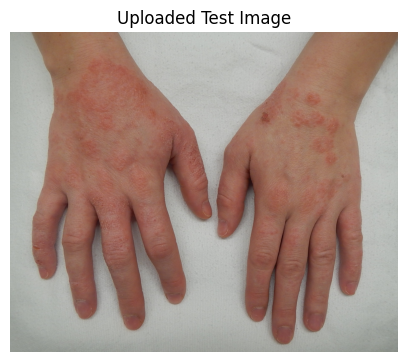

In [ ]:

from google.colab import files

uploaded = files.upload()

image_path = next(iter(uploaded.keys()))

predicted_class, scores = predict_skin_image(image_path)


In [ ]:

import pandas as pd
import os

metadata_path = (
    "/content/skindisnet_data/SkinDisNet_Metadata.csv"
)

df = pd.read_csv(metadata_path)

# Search for the image filename
matches = df[
    df["Image_id"].astype(str).str.contains(
        "eczema.jpg", case=False, na=False
    )
]

print(matches[["Image_id", "Diagnosis", "Folder_name"]].head(10))


FileNotFoundError: [Errno 2] No such file or directory: '/content/skindisnet_data/SkinDisNet_Metadata.csv'

In [ ]:
import os

# Check the expected location
print("Dataset folder exists:",
      os.path.exists("/content/skindisnet_data"))

# Search Google Drive for the metadata file
for root, dirs, files_list in os.walk(
    "/content/drive/MyDrive/SkinDisNet_Project"
):
    for filename in files_list:
        if filename.lower().endswith(".csv") and "metadata" in filename.lower():
            print("Found:", os.path.join(root, filename))

Dataset folder exists: False


In [ ]:
import os

project_path = "/content/drive/MyDrive/SkinDisNet_Project"

print("Project folder exists:", os.path.exists(project_path))

if os.path.exists(project_path):
    for item in os.listdir(project_path):
        print(item)


Project folder exists: True
SkinDisNet_2.zip
skindisnet_efficientnet_b0.pth
skindisnet_partial_best.pth
partial_training_history.json
skindisnet_balanced_best.pth
balanced_training_history.json
skindisnet_groupbalanced_best.pth
groupbalanced_training_history.json


In [ ]:
import zipfile
import os

zip_path = "/content/drive/MyDrive/SkinDisNet_Project/SkinDisNet_2.zip"
extract_path = "/content/skindisnet_data"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")
print("Extracted folders:", os.listdir(extract_path))

Dataset extracted successfully!
Extracted folders: ['SkinDisNet_Metadata.csv', 'Augmented', 'Preprocessed']


In [ ]:
import os

for root, dirs, files_list in os.walk("/content/skindisnet_data"):
    for filename in files_list:
        if "metadata" in filename.lower() and filename.lower().endswith(".csv"):
            print("Metadata found:", os.path.join(root, filename))

Metadata found: /content/skindisnet_data/SkinDisNet_Metadata.csv


In [ ]:

import pandas as pd

metadata_path = "/content/skindisnet_data/SkinDisNet_Metadata.csv"
df = pd.read_csv(metadata_path)

print("Metadata columns:")
print(df.columns.tolist())

print("\nRows matching eczema.jpg:")
matches = df[
    df["Image_id"].astype(str).str.contains(
        "eczema.jpg", case=False, na=False
    )
]

if len(matches) > 0:
    print(matches[["Image_id", "Diagnosis", "Folder_name"]].to_string(index=False))
else:
    print("No exact filename match found.")
    print("\nExample image IDs:")
    print(df["Image_id"].head(10).to_list())


Metadata columns:
['Folder_name', 'Patient_id', 'Image_id', 'Age', 'Sex', 'Leision_location', 'Diagnosis']

Rows matching eczema.jpg:
No exact filename match found.

Example image IDs:
['AD (1)', 'AD (2)', 'AD (3)', 'AD (4)', 'AD (5)', 'AD (6)', 'AD (7)', 'AD (8)', 'AD (9)', 'AD (10)']


In [ ]:

# Display examples of image IDs and their actual labels
print(
    df[["Image_id", "Folder_name", "Diagnosis"]]
    .head(20)
    .to_string(index=False)
)

print("\nAvailable diagnosis labels:")
print(df["Diagnosis"].value_counts())


Image_id            Folder_name         Diagnosis
  AD (1) Atopic Dermatitis (AD) Atopic Dermatitis
  AD (2) Atopic Dermatitis (AD) Atopic Dermatitis
  AD (3) Atopic Dermatitis (AD) Atopic Dermatitis
  AD (4) Atopic Dermatitis (AD) Atopic Dermatitis
  AD (5) Atopic Dermatitis (AD) Atopic Dermatitis
  AD (6) Atopic Dermatitis (AD) Atopic Dermatitis
  AD (7) Atopic Dermatitis (AD) Atopic Dermatitis
  AD (8) Atopic Dermatitis (AD) Atopic Dermatitis
  AD (9) Atopic Dermatitis (AD) Atopic Dermatitis
 AD (10) Atopic Dermatitis (AD) Atopic Dermatitis
 AD (11) Atopic Dermatitis (AD) Atopic Dermatitis
 AD (12) Atopic Dermatitis (AD) Atopic Dermatitis
 AD (13) Atopic Dermatitis (AD) Atopic Dermatitis
 AD (14) Atopic Dermatitis (AD) Atopic Dermatitis
 AD (15) Atopic Dermatitis (AD) Atopic Dermatitis
 AD (16) Atopic Dermatitis (AD) Atopic Dermatitis
 AD (17) Atopic Dermatitis (AD) Atopic Dermatitis
 AD (18) Atopic Dermatitis (AD) Atopic Dermatitis
 AD (19) Atopic Dermatitis (AD) Atopic Dermatitis


In [ ]:

import os

# Filter metadata for Eczema
eczema_rows = df[
    df["Diagnosis"].astype(str).str.strip().str.lower() == "eczema"
]

print("Eczema images in metadata:", len(eczema_rows))
print(eczema_rows[["Image_id", "Folder_name", "Diagnosis"]].head(10))

# Search for the corresponding image files
image_root = "/content/skindisnet_data"

for root, dirs, files_list in os.walk(image_root):
    for filename in files_list:
        if filename.lower().endswith((".jpg", ".jpeg", ".png")):
            if "eczema" in root.lower():
                print("Example image path:", os.path.join(root, filename))
                break
    else:
        continue
    break


Eczema images in metadata: 466
    Image_id  Folder_name Diagnosis
547   EC (1)  Eczema (EC)    Eczema
548   EC (2)  Eczema (EC)    Eczema
549   EC (3)  Eczema (EC)    Eczema
550   EC (4)  Eczema (EC)    Eczema
551   EC (5)  Eczema (EC)    Eczema
552   EC (6)  Eczema (EC)    Eczema
553   EC (7)  Eczema (EC)    Eczema
554   EC (8)  Eczema (EC)    Eczema
555   EC (9)  Eczema (EC)    Eczema
556  EC (10)  Eczema (EC)    Eczema
Example image path: /content/skindisnet_data/Augmented/Eczema (EC)/EC (65)_06.jpg


In [ ]:

import os

preprocessed_path = "/content/skindisnet_data/Preprocessed"

print("Preprocessed folder exists:", os.path.exists(preprocessed_path))

for root, dirs, files_list in os.walk(preprocessed_path):
    for filename in files_list:
        if filename.lower().endswith((".jpg", ".jpeg", ".png")):
            if "eczema" in root.lower():
                print("Original Eczema image:", os.path.join(root, filename))
                break
    else:
        continue
    break


Preprocessed folder exists: True
Original Eczema image: /content/skindisnet_data/Preprocessed/Eczema (EC)/EC (311).jpg


Predicted class: Eczema

Scores for each class:
Atopic Dermatitis: 0.05%
Contact Dermatitis: 0.04%
Eczema: 99.58%
Scabies: 0.13%
Seborrheic Dermatitis: 0.20%
Tinea Corporis: 0.01%


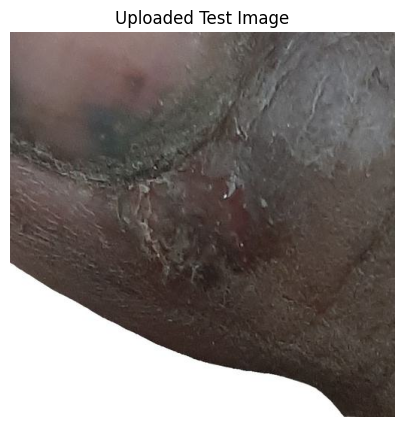


Actual dataset label: Eczema
Model prediction: Eczema


In [ ]:

image_path = "/content/skindisnet_data/Preprocessed/Eczema (EC)/EC (311).jpg"

predicted_class, scores = predict_skin_image(image_path)

print("\nActual dataset label: Eczema")
print("Model prediction:", predicted_class)
